# Transaction Anomaly Checker

A small project that looks for suspicious or incorrect transactions in a business's payment records: duplicate payments, unusually large amounts, payments kept just under an approval limit, and payments with no approver on file.

I built this after helping review my family's business records when an employee had been hiding transactions. I didn't have a real dataset I could share publicly, so this notebook simulates 500 transactions with a few problems planted on purpose, then runs the same kind of checks I'd want to run on real records.

**Tools:** Python, pandas, NumPy, Matplotlib, Google Colab

## 1. Create a simulated dataset

Since I can't share real financial data, I generate 500 fake transactions across six vendors, then plant four kinds of problems on purpose:
- 8 duplicate payments
- 10 unusually large amounts
- 25 payments just under the $500 approval limit
- 10 payments with no approver listed

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 500

vendors = ["Office Depot", "Fresh Foods Co", "City Utilities", "Print Shop", "Delivery Express", "Tech Supplies"]
categories = {
    "Office Depot": "Supplies",
    "Fresh Foods Co": "Inventory",
    "City Utilities": "Utilities",
    "Print Shop": "Marketing",
    "Delivery Express": "Shipping",
    "Tech Supplies": "Equipment",
}

df = pd.DataFrame({
    "id": range(1, n + 1),
    "date": pd.to_datetime("2025-01-01") + pd.to_timedelta(np.random.randint(0, 180, n), unit="D"),
    "vendor": np.random.choice(vendors, n),
    "amount": np.round(np.random.lognormal(mean=5, sigma=0.5, size=n), 2),
    "approved_by": np.random.choice(["Person A", "Person B", "Manager"], n),
})
df["category"] = df["vendor"].map(categories)

# Plant four kinds of problems so the checks below have something to find
# 1. Duplicated payments
dupes = df.sample(8, random_state=1).copy()
dupes["id"] = range(n + 1, n + 9)
df = pd.concat([df, dupes], ignore_index=True)

# 2. Unusually large amounts
big = df.sample(10, random_state=2).index
df.loc[big, "amount"] *= 10

# 3. Payments just under the $500 approval limit
near = df.sample(25, random_state=3).index
df.loc[near, "amount"] = np.round(np.random.uniform(470, 499.99, 25), 2)

# 4. Missing approver
blank = df.sample(10, random_state=4).index
df.loc[blank, "approved_by"] = np.nan

df = df.sort_values("date").reset_index(drop=True)
df.head(10)

,id,date,vendor,amount,approved_by,category
0,123,2025-01-01,Office Depot,154.35,Person A,Supplies
1,437,2025-01-01,City Utilities,479.35,Person B,Utilities
2,475,2025-01-01,Delivery Express,132.83,Manager,Shipping
3,194,2025-01-02,Print Shop,139.67,Manager,Marketing
4,248,2025-01-02,Office Depot,110.25,Manager,Supplies
5,19,2025-01-02,Fresh Foods Co,143.19,Person A,Inventory
6,481,2025-01-02,City Utilities,68.12,Person A,Utilities
7,65,2025-01-02,Delivery Express,337.33,Person B,Shipping
8,220,2025-01-03,City Utilities,168.78,Person A,Utilities
9,168,2025-01-03,Delivery Express,185.02,Person B,Shipping


## 2. Flagging suspicious transactions

Four checks run over the data:
1. **Duplicates** — same date, vendor, and amount appearing more than once.
2. **Outliers** — amounts far above the normal range for their category, using the IQR rule (values beyond Q3 + 3 x IQR).
3. **Just-under-the-limit payments** — amounts between \$470 and \$499.99, just below the \$500 approval threshold.
4. **Missing approver** — no name on file for who approved the payment.

In [2]:
# 1. Exact duplicates: same date, vendor, and amount
df["flag_duplicate"] = df.duplicated(subset=["date", "vendor", "amount"], keep=False)

# 2. Statistical outliers within each category, using the IQR rule
q1 = df.groupby("category")["amount"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby("category")["amount"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["flag_outlier"] = df["amount"] > q3 + 3 * iqr

# 3. Payments just under the $500 approval limit
threshold = 500
df["flag_under_threshold"] = (df["amount"] < threshold) & (df["amount"] >= 0.94 * threshold)

# 4. Missing approver
df["flag_no_approver"] = df["approved_by"].isna()

df[["id", "date", "vendor", "amount", "flag_duplicate", "flag_outlier", "flag_under_threshold", "flag_no_approver"]].head(10)

,id,date,vendor,amount,flag_duplicate,flag_outlier,flag_under_threshold,flag_no_approver
0,123,2025-01-01,Office Depot,154.35,False,False,False,False
1,437,2025-01-01,City Utilities,479.35,False,False,True,False
2,475,2025-01-01,Delivery Express,132.83,False,False,False,False
3,194,2025-01-02,Print Shop,139.67,False,False,False,False
4,248,2025-01-02,Office Depot,110.25,False,False,False,False
5,19,2025-01-02,Fresh Foods Co,143.19,False,False,False,False
6,481,2025-01-02,City Utilities,68.12,False,False,False,False
7,65,2025-01-02,Delivery Express,337.33,False,False,False,False
8,220,2025-01-03,City Utilities,168.78,False,False,False,False
9,168,2025-01-03,Delivery Express,185.02,False,False,False,False


## 3. Summarizing the flagged transactions

Each transaction gets a `total_flags` score (how many checks it tripped). Pulling out everything with at least one flag makes it easier to see what actually needs our attention.

In [3]:
flag_cols = [c for c in df.columns if c.startswith("flag_")]
df["total_flags"] = df[flag_cols].sum(axis=1)

suspicious = df[df["total_flags"] > 0].sort_values("total_flags", ascending=False)
print(len(suspicious), "flagged out of", len(df), "transactions")

suspicious[["id", "date", "vendor", "amount", "total_flags"]]

62 flagged out of 508 transactions


,id,date,vendor,amount,total_flags
1,437,2025-01-01,City Utilities,479.35,1
16,405,2025-01-06,Delivery Express,103.37,1
34,74,2025-01-14,Fresh Foods Co,485.07,1
35,503,2025-01-14,Delivery Express,66.24,1
36,48,2025-01-14,Delivery Express,66.24,1
...,...,...,...,...,...
437,385,2025-06-02,Office Depot,481.96,1
461,334,2025-06-10,Print Shop,484.61,1
475,499,2025-06-17,Fresh Foods Co,473.97,1
486,56,2025-06-21,Print Shop,256.00,1


## 4. Visualizing the results

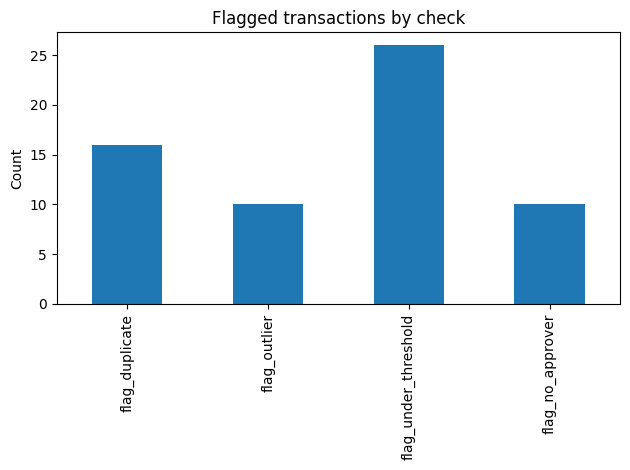

In [4]:
df[flag_cols].sum().plot(kind="bar", title="Flagged transactions by check")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

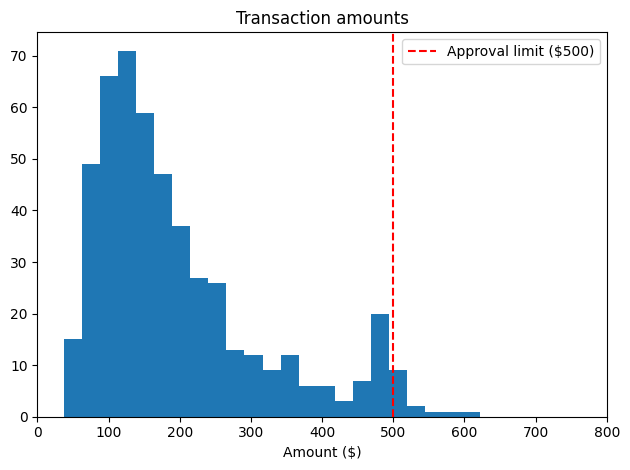

In [5]:
plt.hist(df["amount"], bins=100)
plt.axvline(threshold, color="red", linestyle="--", label="Approval limit ($500)")
plt.title("Transaction amounts")
plt.xlabel("Amount ($)")
plt.legend()
plt.xlim(0, 800)
plt.tight_layout()
plt.show()

## Conclusion

Out of 500 simulated transactions, the checks caught the problems I'd planted beforehand without me telling the code which rows they were. The project reflects something I actually dealt with, which was an issue with hidden transactions my family's business had encountered, I helped review the records by hand. This notebook is my first attempt at automating that kind of first-pass check.

**Limitations:** the rules use fixed thresholds and outlier limits I chose, not ones learned from data, so they won't catch every kind of problem, and a few normal transactions may get flagged along with the real ones (false positives).

**Next steps:** try this on real anonymized data, add a small dashboard to explore the flagged transactions interactively, and compare this rule-based approach to a simple anomaly-detection model like Isolation Forest.